## Customer churn prediction



# 01 — Business Understanding

## Business problem
A telecom company wants to reduce the number of customers who leave.
Our goal is to predict which customers are likely to stop using its services.
We will use customer information to train and compare machine learning models.
The company could use these predictions to contact customers early
and offer suitable support.

## Target column
The target is `Churn`, which is the answer we want to predict:
- Yes: the customer left.
- No: the customer stayed.

## Why this is classification
We predict a category, Yes or No, rather than a number.
There are two possible categories, so this is binary classification.
For evaluation, Yes is the positive class: the event we want to detect.

## How the business can use predictions
1. Contact customers at risk and help resolve service problems.
2. Offer a suitable plan or retention offer to customers at risk.

## Why missing a likely churner is costly
A false negative means the model predicts that a customer will stay,
but the customer actually leaves.
The company misses a chance to help that customer and may lose future income.
It may also spend money attracting a replacement customer.

-----------------------------------------------------------

## Load and Explore Data


In [1]:
import pandas as pd 

df=pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Column names: ")
print(df.columns.tolist())

Column names: 
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [3]:
df.shape

(7043, 21)

In [4]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### Column roles

- Identifier: `customerID` identifies each customer and is excluded from model inputs.
- Numerical inputs: `tenure`, `MonthlyCharges`, and `TotalCharges`. `TotalCharges` is initially stored as text and is converted below.
- Categorical inputs: all other input columns, including `SeniorCitizen`, where 0 and 1 represent categories.
- Target: `Churn` (Yes or No).


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:

print(df["Churn"].value_counts())


print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


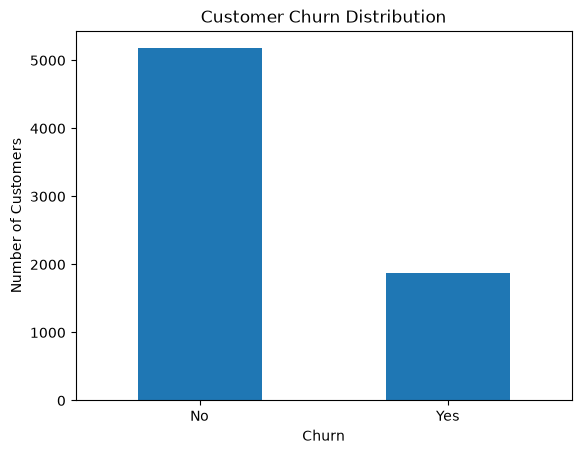

In [9]:
import matplotlib.pyplot as plt

df['Churn'].value_counts().plot(kind="bar",rot=0)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

73.46% of customers stayed, while 26.54% churned. The classes are imbalanced, so accuracy alone is not enough.


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Yes, dtype: float64


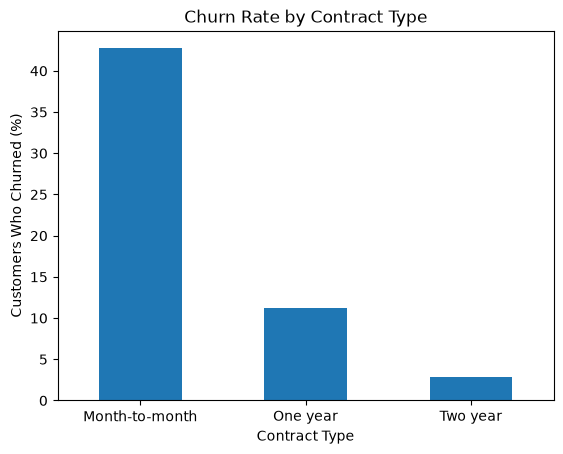

In [10]:

contract_churn = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
)["Yes"] * 100

print(contract_churn.round(2))


contract_churn.plot(kind="bar", rot=0)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers Who Churned (%)")
plt.show()

Month-to-month customers have a higher churn rate than customers
with one-year or two-year contracts. This shows an association
between contract type and churn, but does not prove causation.

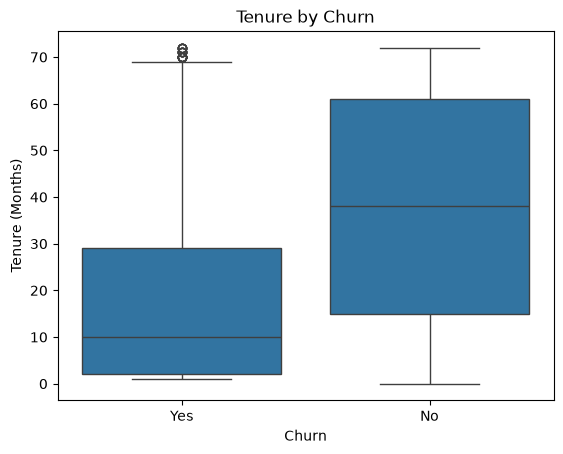

In [11]:
import seaborn as sns

sns.boxplot(data=df, x='Churn', y='tenure' , order=["Yes","No"])
plt.title("Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

In [12]:

df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

Customers who churned had a median tenure of 10 months,
compared with 38 months for customers who stayed.
Customers who left generally had a shorter time with the company.

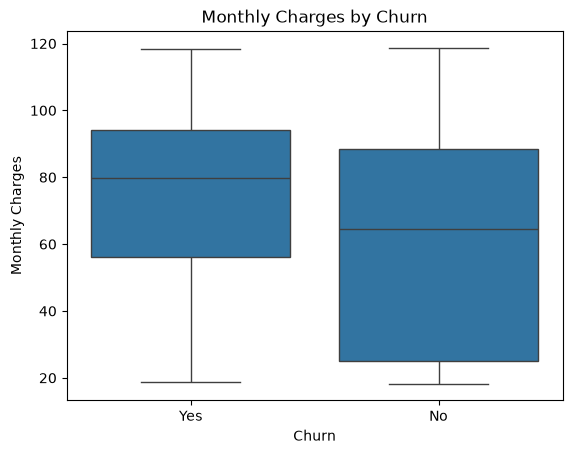

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [13]:
sns.boxplot(data=df,x='Churn', y='MonthlyCharges',order=["Yes","No"])
plt.title("Monthly Charges by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()
print(df.groupby("Churn")["MonthlyCharges"].median())

Customers who churned had a median monthly charge of 79.65,
compared with 64.43 for customers who stayed.
Higher monthly charges are associated with churn, but this
does not prove that higher charges caused customers to leave.

# 03 — Split and Preprocessing


In [14]:
print("Blank TotalCharges:", df["TotalCharges"].str.strip().eq("").sum())

Blank TotalCharges: 11


In [15]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

df = df.drop(columns=["customerID"])
print("Data type: ",df['TotalCharges'].dtype)
print("Missing values: ",df["TotalCharges"].isna().sum())

Data type:  float64
Missing values:  11


The 11 blank strings in `TotalCharges` were not counted as missing by `info()`. Converting this column to numeric changed those blanks to missing values. The pipeline fills them using the median learned from training data only.


In [16]:
from sklearn.model_selection import train_test_split

X=df.drop(columns=["Churn"])

y=df["Churn"].map({"Yes":1 , "No": 0})
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (5634, 19)
Testing: (1409, 19)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , StandardScaler

numeric_columns=["tenure","MonthlyCharges","TotalCharges"]

categorical_columns = [
    col for col in X_train.columns if col not in numeric_columns
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessor ready")

Preprocessor ready


# 04 — Baseline


In [18]:
from sklearn.dummy import DummyClassifier

baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

baseline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}


scores = cross_validate(
    baseline, X_train, y_train, cv=cv, scoring=scoring
)


results = [{
    "Model": "Baseline",
    "Accuracy": scores["test_accuracy"].mean(),
    "Precision": scores["test_precision"].mean(),
    "Recall": scores["test_recall"].mean(),
    "F1": scores["test_f1"].mean()
}]

display(pd.DataFrame(results).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.735,0.0,0.0,0.0


The baseline achieved 73.5% accuracy by predicting that every customer
would stay. Its churn recall and F1 were zero, showing that accuracy
alone is not enough for this problem.

# 05 — Model Comparison

The table and confusion matrices below use five-fold cross-validation on the training data. Churn = Yes (1) is the positive class. The test set is reserved for final evaluation.


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

log_model=Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000))
])

scores = cross_validate(
    log_model, X_train, y_train, cv=cv, scoring=scoring
)

results.append({
    "Model": "Logistic Regression",
    "Accuracy": scores["test_accuracy"].mean(),
    "Precision": scores["test_precision"].mean(),
    "Recall": scores["test_recall"].mean(),
    "F1": scores["test_f1"].mean()
})

display(pd.DataFrame(results).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.735,0.000,0.000,0.000
1,Logistic Regression,0.803,0.655,0.543,0.593


In [21]:
from sklearn.tree import DecisionTreeClassifier

tree_model=Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", DecisionTreeClassifier(random_state=42))
])

scores = cross_validate(
    tree_model, X_train, y_train, cv=cv, scoring=scoring
)

results.append({
    "Model": "Decision Tree",
    "Accuracy": scores["test_accuracy"].mean(),
    "Precision": scores["test_precision"].mean(),
    "Recall": scores["test_recall"].mean(),
    "F1": scores["test_f1"].mean()
})

display(pd.DataFrame(results).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.735,0.000,0.000,0.000
1,Logistic Regression,0.803,0.655,0.543,0.593
2,Decision Tree,0.730,0.491,0.498,0.494


In [22]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

scores = cross_validate(
    forest_model, X_train, y_train, cv=cv, scoring=scoring
)

results.append({
    "Model": "Random Forest",
    "Accuracy": scores["test_accuracy"].mean(),
    "Precision": scores["test_precision"].mean(),
    "Recall": scores["test_recall"].mean(),
    "F1": scores["test_f1"].mean()
})

display(pd.DataFrame(results).round(3))

,Model,Accuracy,Precision,Recall,F1
0,Baseline,0.735,0.000,0.000,0.000
1,Logistic Regression,0.803,0.655,0.543,0.593
2,Decision Tree,0.730,0.491,0.498,0.494
3,Random Forest,0.784,0.624,0.475,0.539


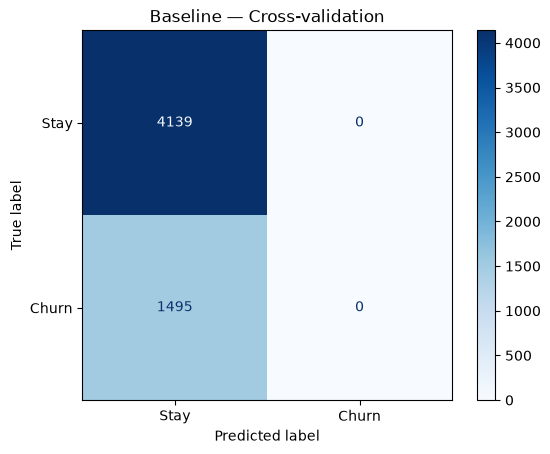

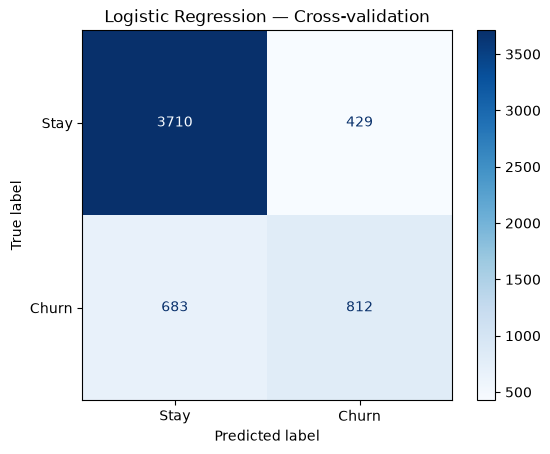

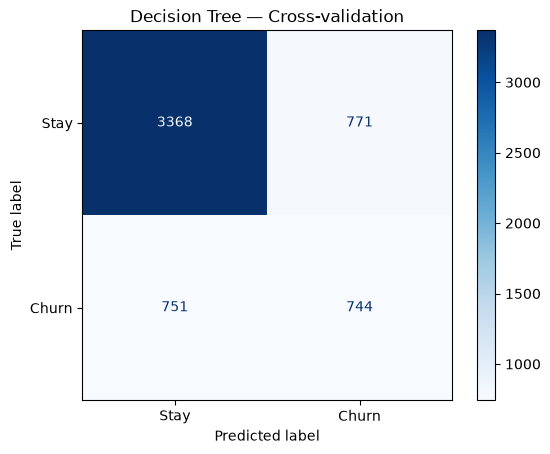

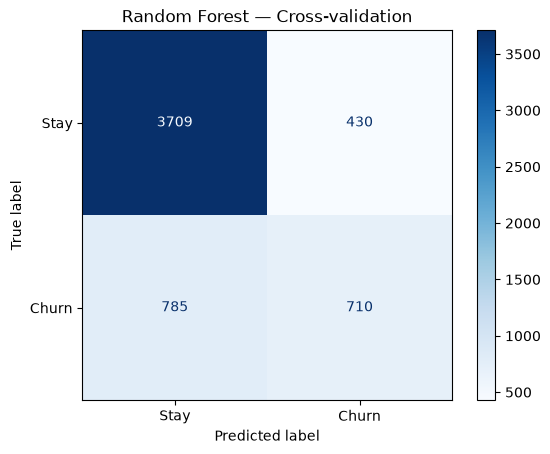

In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

models = {
    "Baseline": baseline,
    "Logistic Regression": log_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

for name, model in models.items():

    predictions = cross_val_predict(
        model, X_train, y_train, cv=cv
    )
    ConfusionMatrixDisplay.from_predictions(
        y_train, predictions,
        labels=[0, 1],
        display_labels=["Stay", "Churn"],
        cmap="Blues"
    )
    plt.title(name + " — Cross-validation")
    plt.show()

Recall is the main business priority because missing a customer who
will leave means losing a chance to intervene. Precision also matters
because false alarms can waste retention offers. F1 helps us compare
the balance between precision and recall.

Logistic Regression currently has the highest cross-validation
recall and F1 among the models tested.

# 06 — Tuning


In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

search = GridSearchCV(
    estimator=log_model,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train,y_train)

best_model=search.best_estimator_

print("Best settings:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 3))

i = search.best_index_
for metric in scoring:
    score = search.cv_results_[f"mean_test_{metric}"][i]
    print(f"{metric}: {score:.3f}")

Best settings: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best CV F1: 0.629
accuracy: 0.750
precision: 0.519
recall: 0.797
f1: 0.629


Tuning increased cross-validation F1 from 0.593 to 0.629
and recall from 0.543 to 0.797. However, precision decreased
from 0.655 to 0.519, meaning more false alarms.

I selected the tuned Logistic Regression because identifying
customers who may leave is the main business priority.
These are model-selection results; the held-out test set
will provide the final evaluation.

The cross-validation F1 improvement was modest, from 0.593 to 0.629 (3.6 percentage points). Recall improved substantially, from 0.543 to 0.797, but precision decreased, producing more false alarms. Business value still needs to be checked in a retention pilot.


# 07 — Final Evaluation


Accuracy: 0.742
Precision: 0.509
Recall: 0.786
F1: 0.618


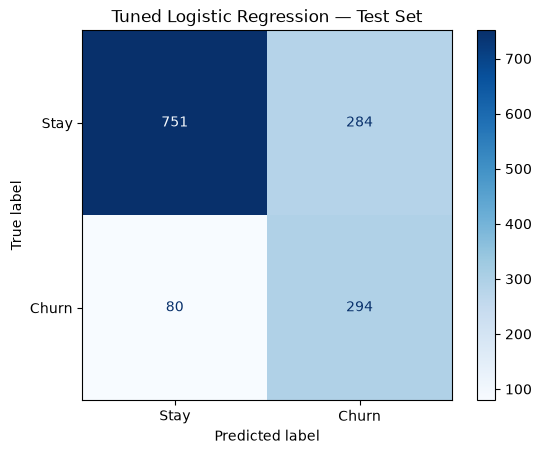

TN: 751, FP: 284, FN: 80, TP: 294


In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix


y_pred = best_model.predict(X_test)


print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_test, y_pred, zero_division=0), 3))


ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=["Stay", "Churn"],
    cmap="Blues"
)
plt.title("Tuned Logistic Regression — Test Set")
plt.show()


tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
print(f"TN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

The final model achieved 74.2% accuracy, 50.9% precision,
78.6% recall, and 61.8% F1 on the held-out test set.

It identified most customers who churned, but approximately half
of its churn alerts were false alarms. Test results were close
to cross-validation results.

------------------------------------------------------------------

# 08 — Business Recommendations



## Final confusion matrix
- True negatives: 751 customers correctly predicted to stay.
- False positives: 284 customers incorrectly predicted to leave.
- False negatives: 80 customers who left were missed.
- True positives: 294 customers correctly predicted to leave.

The model detected 294 out of 374 customers who churned.

## Important patterns
1. Month-to-month customers had higher churn rates than customers
   with one-year or two-year contracts.
2. Customers who churned had a median tenure of 10 months,
   compared with 38 months for customers who stayed.

These patterns show associations, not proof of causation.

## Business actions
1. Contact customers flagged as at risk to identify and resolve
   service problems.
2. Review their needs and offer suitable plans or targeted retention
   offers when appropriate.

## Limitations
- The target classes are imbalanced, so accuracy alone is misleading.
- There were 284 false alarms, which could waste time or discounts.
- Results from this teaching dataset may not match current customers.
- Predicting churn does not prove that an offer will prevent it.

## Recommendation
Use the tuned Logistic Regression to support a small retention pilot.
It achieved 78.6% test recall and 61.8% test F1.
Start with low-cost support calls because precision was only 50.9%.
Measure retention outcomes and intervention costs before wider use.

# 09 — Save and Use the Pipeline

Run the saving cell after the training and tuning cells. It saves the fitted preprocessing steps and final model together. No retraining is needed when loading the saved file.


In [26]:
import joblib

# Save the complete fitted pipeline in the notebook folder.
joblib.dump(best_model, "churn_pipeline.joblib")
print("Saved: churn_pipeline.joblib")


Saved: churn_pipeline.joblib


### Use the saved pipeline

Keep `churn_pipeline.joblib` in the working folder. Run the example below after the earlier notebook cells; it uses one existing test row only to demonstrate loading and prediction, without repeating evaluation or tuning.

For new customers, supply the same 19 input columns used in `X_train`, without `customerID` or `Churn`. Convert `TotalCharges` to numeric with `errors="coerce"` before prediction, as done during preparation. The saved pipeline handles missing values, encoding, and scaling. Predictions use 1 = churn and 0 = stay. Use the same Python and package versions as the training environment.


In [27]:
# Load the fitted pipeline.
loaded_model = joblib.load("churn_pipeline.joblib")

# Demonstrate prediction using one row with the required input columns.
customer = X_test.iloc[[0]].copy()
prediction = loaded_model.predict(customer)[0]
print("Prediction:", "Churn" if prediction == 1 else "Stay")


Prediction: Stay
